# ViT：用张量形状读懂 Vision Transformer

这份 Notebook **只做随机输入的前向传播，不训练、不下载数据、不需要预训练权重**。依次运行单元格，观察图片怎样变成 patch tokens，再经过多头注意力和 MLP 得到 logits。

对应论文：Dosovitskiy et al., *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale* (ICLR 2021), [arXiv:2010.11929](https://arxiv.org/abs/2010.11929)。

若从 Jupyter 在其他目录启动，请先将工作目录切换到本 Notebook 所在目录，或确保 `vit_model.py` 在 Python 导入路径中。

In [1]:
import torch
from vit_model import ViT, patchify, count_parameters, parameter_breakdown

device = 'cuda'  # set to 'cuda' if available and preferred
print('device:', device, '| torch:', torch.__version__)

device: cuda | torch: 2.11.0+cu128


## 1. 先用一张小图片手动切 patch

教学版设定：28×28 灰度图，每块 4×4 像素。切成 7×7=49 个 patches，每个 patch 展平后有 16 个数。此处的 `patchify` 只负责切块、重排维度，不做线性投影。

In [2]:
image = torch.arange(28 * 28, dtype=torch.float32).reshape(1, 1, 28, 28)
patches = patchify(image, patch_size=4)
print('image: ', tuple(image.shape))
print('patches:', tuple(patches.shape), '= (B=1, N=49, 每块 4×4×1=16 个值)')
print('第 0 个 patch 的像素值：', patches[0, 0].tolist())
print('第 1 个 patch 的像素值：', patches[0, 1].tolist())
print('第 7 个 patch（下一行开头）的像素值：', patches[0, 7].tolist())

image:  (1, 1, 28, 28)
patches: (1, 49, 16) = (B=1, N=49, 每块 4×4×1=16 个值)
第 0 个 patch 的像素值： [0.0, 1.0, 2.0, 3.0, 28.0, 29.0, 30.0, 31.0, 56.0, 57.0, 58.0, 59.0, 84.0, 85.0, 86.0, 87.0]
第 1 个 patch 的像素值： [4.0, 5.0, 6.0, 7.0, 32.0, 33.0, 34.0, 35.0, 60.0, 61.0, 62.0, 63.0, 88.0, 89.0, 90.0, 91.0]
第 7 个 patch（下一行开头）的像素值： [112.0, 113.0, 114.0, 115.0, 140.0, 141.0, 142.0, 143.0, 168.0, 169.0, 170.0, 171.0, 196.0, 197.0, 198.0, 199.0]


## 2. Patch embedding：线性投影变成 token

实际代码把 `Conv2d(kernel_size=P, stride=P)` 用作一次并行的 patch 投影。每个 patch 的像素先映射到 D 维 embedding。下图以论文 ViT-B/16 为例：224×224 RGB → 196 个 16×16 patch → 每个 768 维。

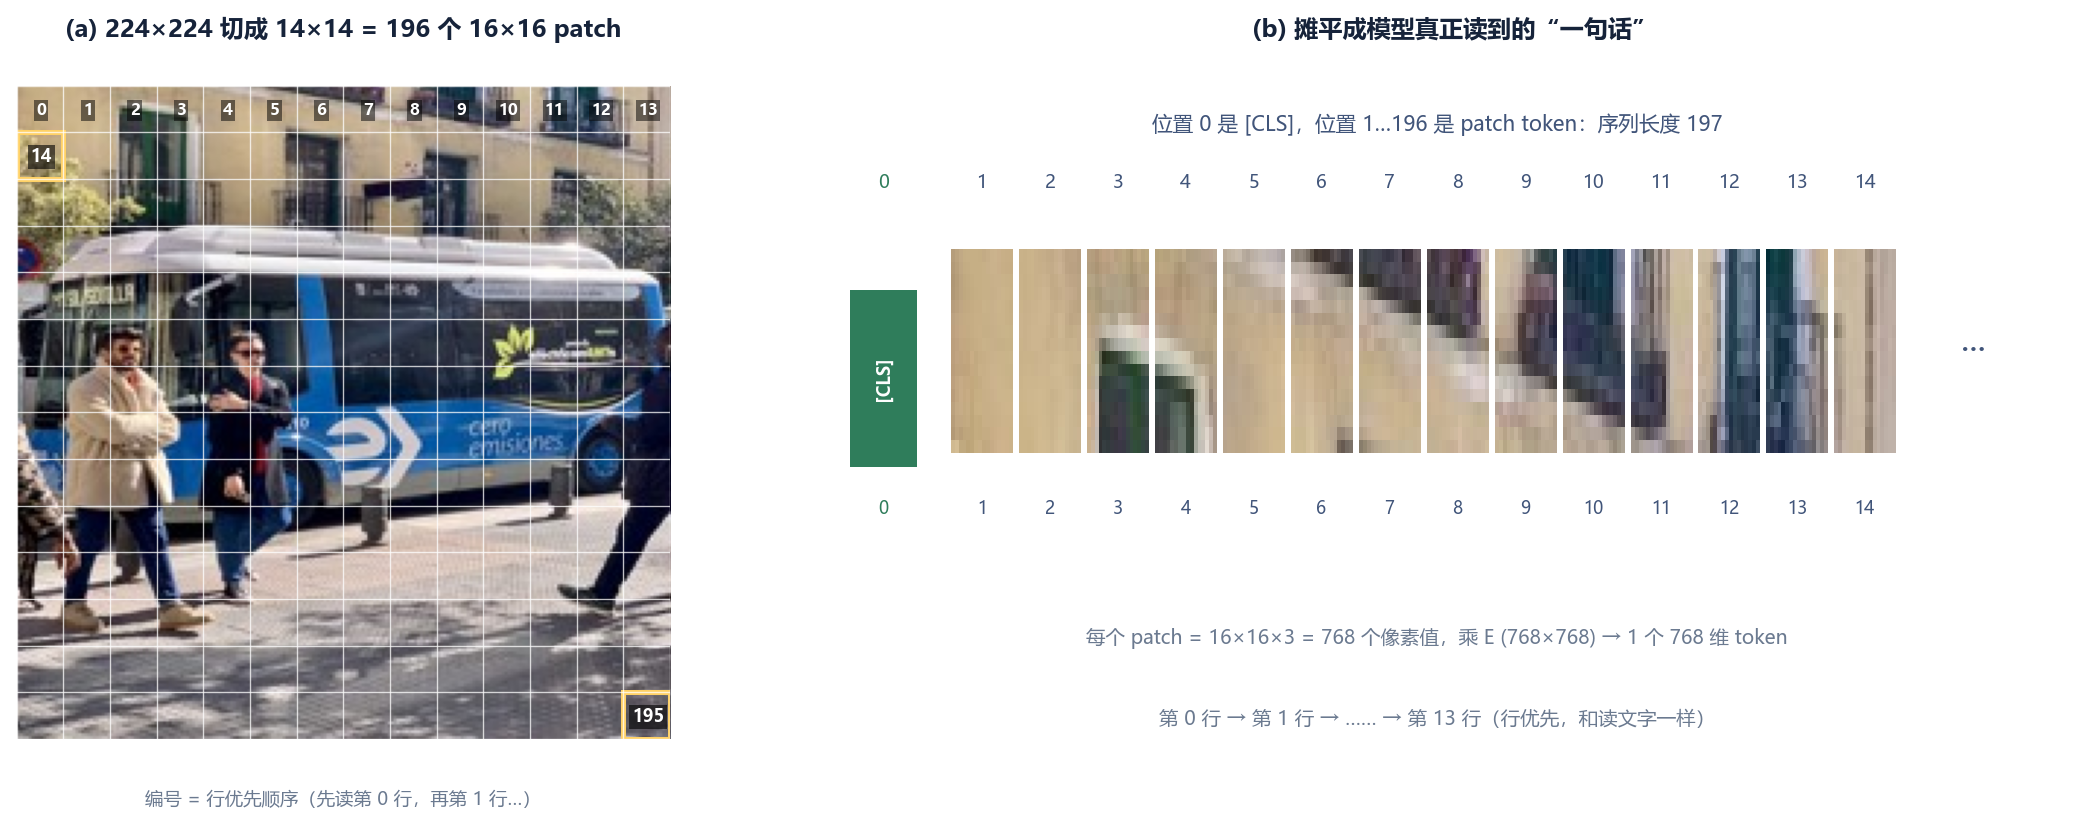

In [2]:
import matplotlib.pyplot as plt
from IPython.display import Image, display
display(Image(filename='assets/patchify.png', width=900))

In [3]:
toy = ViT(img_size=28, patch_size=4, in_chans=1, num_classes=10,
          embed_dim=96, depth=4, num_heads=4).to(device).eval()
x = torch.randn(2, 1, 28, 28, device=device)  # batch of 2 random grayscale images
with torch.no_grad():
    tokens = toy.patch_embed(x)
print('input:      ', tuple(x.shape))
print('patch tokens:', tuple(tokens.shape), '= (B, N=49, D=96)')

input:       (2, 1, 28, 28)
patch tokens: (2, 49, 96) = (B, N=49, D=96)


## 3. `[CLS]` 与位置编码

在 patch 序列前面加一个可学习的 `[CLS]` 向量，再给每个位置加一个可学习的位置向量。位置编码非常关键：纯 self-attention 本身对 token 顺序置换是等变的，并不知道 patch 原本处在图像哪个位置。

In [4]:
cls = toy.cls_token.expand(x.shape[0], -1, -1)
z = torch.cat([cls, tokens], dim=1)
z = z + toy.pos_embed
print('CLS token:', tuple(cls.shape))
print('concat:    ', tuple(z.shape), '= (B, 1+49, D=96)')
print('pos_embed: ', tuple(toy.pos_embed.shape), '，与 token 逐位置相加')

CLS token: (2, 1, 96)
concat:     (2, 50, 96) = (B, 1+49, D=96)
pos_embed:  (1, 50, 96) ，与 token 逐位置相加


## 4. 放大看一个 Transformer Encoder Block

每层维度保持不变。以 ViT-B/16 为例：B×197×768。注意力先算 `QKᵀ`，形成每个 head 的 197×197 token 相关性矩阵，再对 V 加权汇总；MLP 则对每个 token 独立执行 768→3072→768。两段都有 LayerNorm 与残差连接。

In [5]:
block = toy.blocks[0]
h = block.norm1(z)
qkv = block.attn.qkv(h)
q, k, v = qkv.reshape(h.shape[0], h.shape[1], 3,
                       block.attn.num_heads, block.attn.head_dim).permute(2, 0, 3, 1, 4).unbind(0)
scores = (q @ k.transpose(-2, -1)) * block.attn.scale
weights = scores.softmax(dim=-1)
context = weights @ v
context = context.transpose(1, 2).reshape(h.shape)
attn_out = block.attn.proj(context)
z1 = z + attn_out  # first residual
mlp_hidden = block.mlp.act(block.mlp.fc1(block.norm2(z1)))
mlp_out = block.mlp.fc2(mlp_hidden)
z2 = z1 + mlp_out  # second residual

for name, tensor in [('LN input', h), ('QKV joined', qkv), ('Q/K/V per head', q),
                     ('attention scores', scores), ('softmax weights', weights),
                     ('weighted values', context), ('MLP hidden', mlp_hidden),
                     ('block output', z2)]:
    print(f'{name:22s} {tuple(tensor.shape)}')
print('attention 每行权重和（应接近 1）：', weights[0, 0, 0].sum().item())

LN input               (2, 50, 96)
QKV joined             (2, 50, 288)
Q/K/V per head         (2, 4, 50, 24)
attention scores       (2, 4, 50, 50)
softmax weights        (2, 4, 50, 50)
weighted values        (2, 50, 96)
MLP hidden             (2, 50, 384)
block output           (2, 50, 96)
attention 每行权重和（应接近 1）： 1.0


## 5. 整个模型的前向传播

取最后一层归一化后的 `[CLS]` 向量，经分类头变成 logits。这里的权重是随机初始化的，预测类别没有语义；目的只是展示架构与张量形状。

In [6]:
with torch.no_grad():
    logits, all_attn = toy(x, return_attn=True)
print('logits: ', tuple(logits.shape))
print('blocks:', len(all_attn), '| each attention:', tuple(all_attn[0].shape))
print('argmax (随机权重，不代表有效预测):', logits.argmax(dim=-1).tolist())

logits:  (2, 10)
blocks: 4 | each attention: (2, 4, 50, 50)
argmax (随机权重，不代表有效预测): [9, 9]


## 6. 看真实论文规格 ViT-B/16

以下只创建模型并计算参数，不运行巨型随机输入；`arch_trace.py` 会给出完整的 B/16 逐层 shape 跟踪。

In [7]:
paper = ViT(img_size=224, patch_size=16, in_chans=3, num_classes=1000,
            embed_dim=768, depth=12, num_heads=12)
print(f'ViT-B/16: {count_parameters(paper):,} 参数 | {paper.num_patches} patches + CLS | D={paper.embed_dim} | L={paper.depth} | h={paper.num_heads}')
for name, count in parameter_breakdown(paper).items():
    print(f'{name:22s} {count:>12,} ({100*count/count_parameters(paper):4.1f}%)')

ViT-B/16: 86,567,656 参数 | 196 patches + CLS | D=768 | L=12 | h=12
transformer blocks       85,054,464 (98.3%)
head                        769,000 ( 0.9%)
patch_embed                 590,592 ( 0.7%)
pos_embed                   151,296 ( 0.2%)
norm                          1,536 ( 0.0%)
cls_token                       768 ( 0.0%)


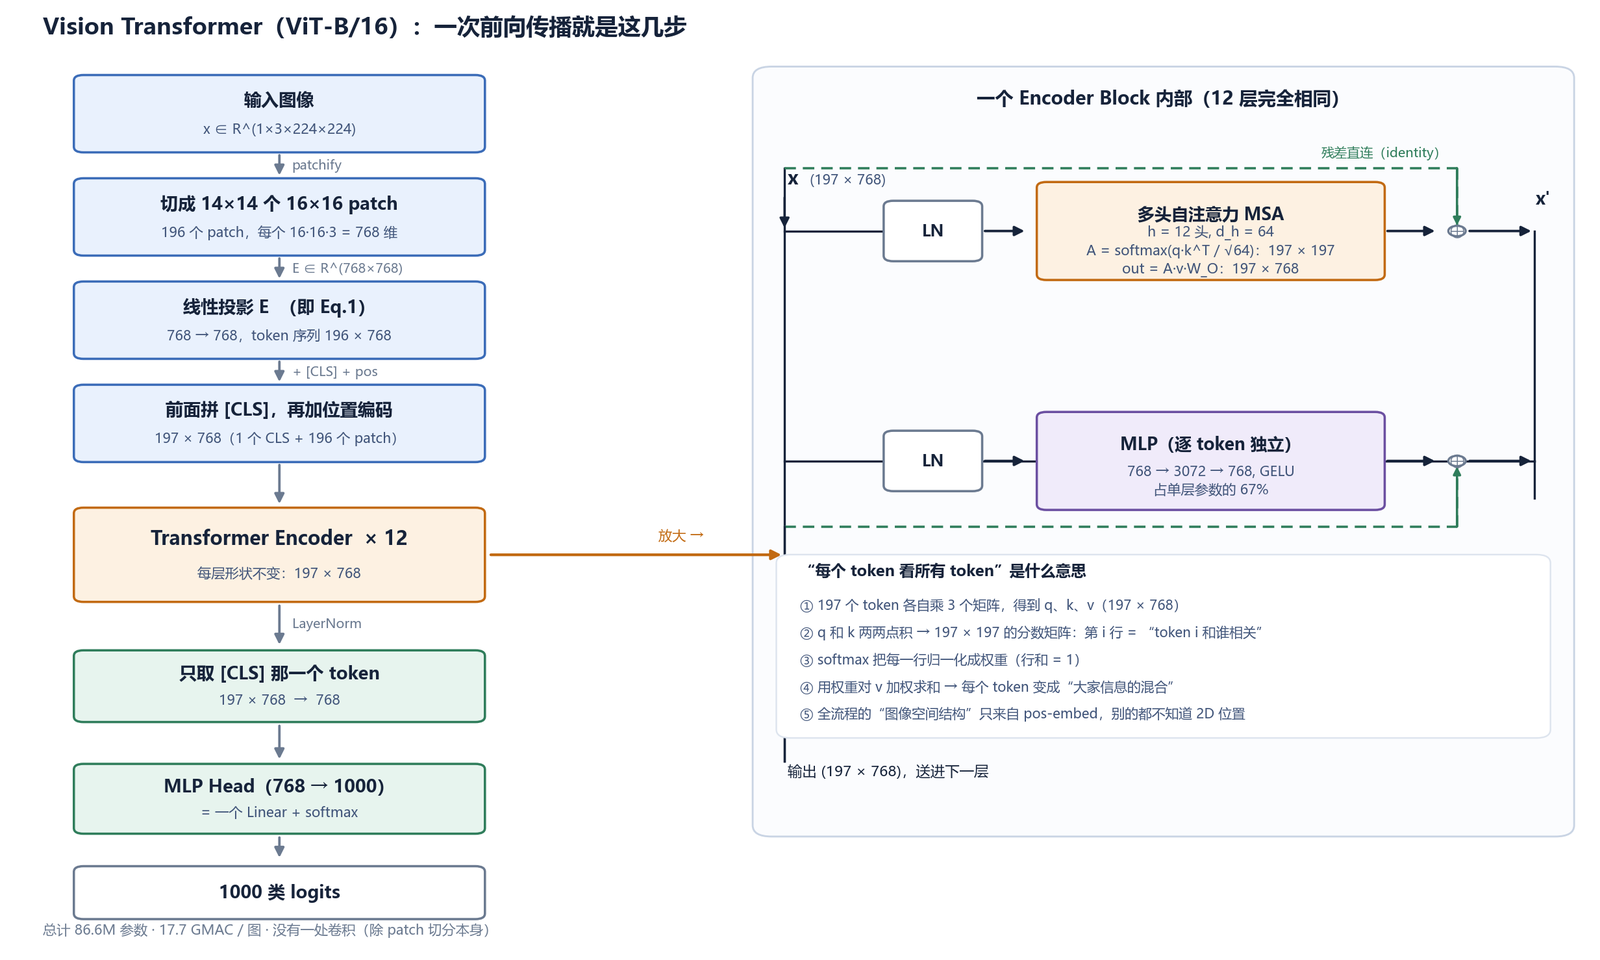

In [8]:
display(Image(filename='assets/vit_architecture.png', width=1100))

## 自己检查理解

- 把 toy 的 `patch_size=4` 改成 `7`：token 数如何变化？
- 把 `depth=4` 改成 `0`：架构中还剩哪些部分？
- `embed_dim=96, num_heads=4` 时每个 head 的维数是多少？
- 为什么 ViT-B/16 的注意力矩阵是 197×197，而不是 196×196？

代码分层可读版：[`vit_model.py`](vit_model.py)；形状跟踪脚本：[`arch_trace.py`](arch_trace.py)；配图生成脚本：[`make_figures.py`](make_figures.py)。